Import Libraries

Load the dair-ai/emotion dataset from Hugging Face. https://huggingface.co/datasets/dair-ai/emotion




In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from datasets import load_dataset

In [2]:
emotion_dataset = load_dataset('dair-ai/emotion')
train_text      = emotion_dataset['train']['text']
train_label     = emotion_dataset['train']['label']

test_text       = emotion_dataset['test']['text']
test_label      = emotion_dataset['test']['label']

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  129kB            

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

In [3]:
label_names = emotion_dataset['train'].features['label'].names

In [4]:
#train
df_train = pd.DataFrame(
    {
        'text': train_text,
        'label':[label_names[i] for i in train_label]
    }
)

#test
df_test = pd.DataFrame(
    {
        'text': test_text,
        'label':[label_names[i] for i in test_label]
    }
)

In [5]:
df_train.isnull().sum()

,0
text,0
label,0


#EDA

<Axes: xlabel='label', ylabel='count'>

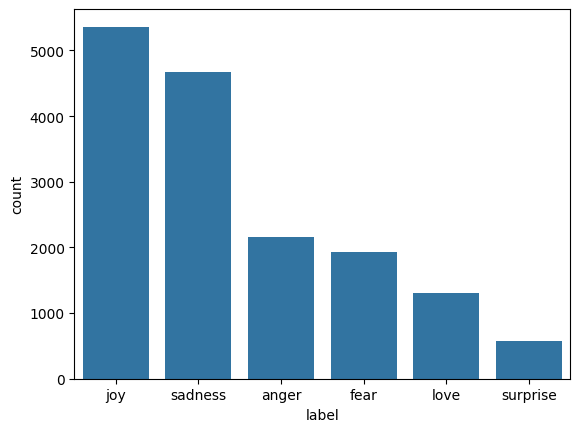

In [6]:
sns.countplot(x= 'label', data =df_train, order =df_train['label'].value_counts(ascending=False).index)

# Data Preprocessing - Using NLP

In [7]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
max_words = 10000

tokenizer = Tokenizer(num_words = max_words, oov_token = '<unk>')
tokenizer.fit_on_texts(df_train['text'])

train_sequence = tokenizer.texts_to_sequences(df_train['text'])
test_sequence = tokenizer.texts_to_sequences(df_test['text'])

padded_train_sequence = pad_sequences(
    train_sequence, maxlen=50, padding='post', truncating='post'
)

padded_test_sequence = pad_sequences(
    test_sequence, maxlen=50, padding='post', truncating='post'
)
train_labels = np.array(train_label)
test_labels = np.array(test_label)

num_classes = len(np.unique(train_labels))
num_classes

print(f"Vocabulary Size: {len(tokenizer.word_index)}")
print(f"Max Sentence Length: {padded_train_sequence.shape[1]}")


Vocabulary Size: 15213
Max Sentence Length: 50


#shared Training Utilities

In [8]:
from sklearn.utils import class_weight
class_weights = class_weight.compute_class_weight(
    class_weight= 'balanced',
    classes     =  np.unique(train_labels),
    y           = train_labels
)

class_weight_dict = dict(enumerate(class_weights))

In [9]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
patience  = 3,
restore_best_weights  = True
)

# Phase 1 — Plain Foundational Models
Train plain .
(non-bidirectional) Simple RNN, Standard LSTM, and Standard GRU models.

#Model 1 — Simple RNN
Plain unrolled Recurrent Neural Network.

In [10]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Embedding, Dense, Dropout, LSTM, GRU

model = Sequential([
    Embedding(input_dim=max_words, output_dim=128, input_length=50),
    SimpleRNN(units=128, return_sequences=True),
    Dropout(0.5),
    SimpleRNN(units=64),
    Dense(units=num_classes, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

rnn_model = model

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [11]:
rnn_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data = [padded_test_sequence, test_labels],
    epochs =20,
    batch_size  = 32,
    validation_split = 0.2,
    class_weight  = class_weight_dict,
    callbacks = [early_stopping]
)

rnn_loss, rnn_accuracy= rnn_model.evaluate(padded_test_sequence,test_labels)
print(f"RNN Loss: {rnn_loss}")
print(f"RNN Accuracy: {rnn_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 27s 48ms/step - accuracy: 0.1511 - loss: 1.8337 - val_accuracy: 0.1920 - val_loss: 1.7531
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 22s 44ms/step - accuracy: 0.1481 - loss: 1.8038 - val_accuracy: 0.1375 - val_loss: 1.8107
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 24s 48ms/step - accuracy: 0.1491 - loss: 1.8015 - val_accuracy: 0.2900 - val_loss: 1.7539
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 25s 49ms/step - accuracy: 0.1637 - loss: 1.7994 - val_accuracy: 0.0355 - val_loss: 1.8293
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.1920 - loss: 1.7531
RNN Loss: 1.75308358669281
RNN Accuracy: 0.19200000166893005


# Model 2 — Standard LSTM
Plain stacked Long Short-Term Memory network.

In [12]:
lstm_model = Sequential([
    Embedding(input_dim = max_words, output_dim = 128 , input_length = 50),
    LSTM(units=128, return_sequences=True),
    Dropout(0.5),
    LSTM(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax') #Output Layer
])

lstm_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

lstm_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

lstm_loss, lstm_accuracy = lstm_model.evaluate(padded_test_sequence, test_labels)
print(f"LSTM Loss: {lstm_loss}")
print(f"LSTM Accuracy: {lstm_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 67s 127ms/step - accuracy: 0.1402 - loss: 1.7942 - val_accuracy: 0.1375 - val_loss: 1.7836
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 63s 126ms/step - accuracy: 0.1610 - loss: 1.7943 - val_accuracy: 0.3440 - val_loss: 1.7871
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 62s 124ms/step - accuracy: 0.1705 - loss: 1.7932 - val_accuracy: 0.1340 - val_loss: 1.7985
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - accuracy: 0.1375 - loss: 1.7836
LSTM Loss: 1.783555030822754
LSTM Accuracy: 0.13750000298023224


#Model 3 — Standard GRU
Plain stacked Gated Recurrent Unit network.

In [13]:
gru_model = Sequential([
    Embedding(input_dim = max_words, output_dim = 128 , input_length = 50),
    GRU(units=128, return_sequences=True),
    Dropout(0.5),
    GRU(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax') #Output Layer
])

gru_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

gru_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

gru_loss, gru_accuracy = gru_model.evaluate(padded_test_sequence, test_labels)
print(f"GRU Loss: {gru_loss}")
print(f"GRU Accuracy: {gru_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 58s 109ms/step - accuracy: 0.1623 - loss: 1.7971 - val_accuracy: 0.0795 - val_loss: 1.8151
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 82s 110ms/step - accuracy: 0.1445 - loss: 1.7946 - val_accuracy: 0.0790 - val_loss: 1.7980
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 81s 108ms/step - accuracy: 0.1412 - loss: 1.7941 - val_accuracy: 0.1390 - val_loss: 1.7592
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.0795 - loss: 1.8151
GRU Loss: 1.8151204586029053
GRU Accuracy: 0.0794999971985817


#Phase 1 Ranking & Selection
Rank foundational models to pick the best base cell for Phase 2.

In [14]:
result_df = pd.DataFrame({
    'Model': ['RNN','LSTM','GRU'],
    'Test Loss' :[rnn_loss, lstm_loss,gru_loss],
    'Test accuracy' :[rnn_accuracy, lstm_accuracy,gru_accuracy]
    }).sort_values(by= 'Test accuracy', ascending=False)
result_df

,Model,Test Loss,Test accuracy
0,RNN,1.753084,0.1920
1,LSTM,1.783555,0.1375
2,GRU,1.815120,0.0795


#phase 2 — Advanced Bidirectional GRU
Enhance GRU with Bidirectional layers, 300D embeddings, and 0.5 dropout regularization.

#Model 4 — Advanced Stacked Bidirectional GRU

In [15]:
from tensorflow.keras.layers import Bidirectional

BiGRU = Sequential([
    Embedding(input_dim = max_words, output_dim = 300 , input_length = 50),
    Bidirectional(GRU(128, return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(64)),
    Dropout(0.5),
    Dense(num_classes, activation='softmax') #Output Layer
    #Why i used num_classes in output layer and what will i get from this.
])

BiGRU.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

BiGRU.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Train & Evaluate Advanced Bidirectional GRU

In [16]:

BiGRU.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 155s 298ms/step - accuracy: 0.5777 - loss: 1.0365 - val_accuracy: 0.8805 - val_loss: 0.3921
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 149s 299ms/step - accuracy: 0.9112 - loss: 0.2551 - val_accuracy: 0.9105 - val_loss: 0.2828
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 147s 295ms/step - accuracy: 0.9432 - loss: 0.1513 - val_accuracy: 0.9195 - val_loss: 0.2252
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 148s 295ms/step - accuracy: 0.9617 - loss: 0.1012 - val_accuracy: 0.9260 - val_loss: 0.2137
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 148s 296ms/step - accuracy: 0.9691 - loss: 0.0891 - val_accuracy: 0.9165 - val_loss: 0.2632
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 209s 311ms/step - accuracy: 0.9728 - loss: 0.0779 - val_accuracy: 0.9130 - val_loss: 0.3223
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 151s 303ms/step - accuracy: 0.9768 - loss: 0.0661 - val_accuracy: 0.9200 - val_loss: 0.3276


In [17]:
BiGRU_loss, BiGRU_accuracy = BiGRU.evaluate(padded_test_sequence, test_labels)
print(f"BiGRU Loss: {BiGRU_loss}")
print(f"BiGRU Accuracy: {BiGRU_accuracy}")


63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 59ms/step - accuracy: 0.9260 - loss: 0.2137
BiGRU Loss: 0.2137470543384552
BiGRU Accuracy: 0.9259999990463257


#Overall Evaluation & Bias Analysis
Consolidate test metrics, plot raw & normalized confusion matrices, and analyze bias.

#Final Model Confusion Matrices (Raw Counts & Normalized %)

63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 91ms/step


<Axes: >

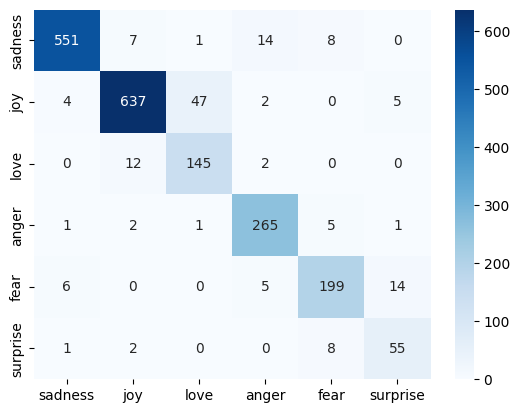

In [18]:
from sklearn.metrics import confusion_matrix

BiGRU_predictions = np.argmax(BiGRU.predict(padded_test_sequence),axis=1)

sns.heatmap(confusion_matrix(test_label, BiGRU_predictions),annot=True, fmt='d', cmap='Blues', xticklabels=label_names, yticklabels=label_names)


In [19]:

sample_texts = [
    "I can't believe how happy I am right now, this is amazing!",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I was shocked and completely surprised by the unexpected gift!"
]

sample_sequences = tokenizer.texts_to_sequences(sample_texts)
sample_padded_sequences = pad_sequences(sample_sequences, maxlen=50, padding='post', truncating='post')

sample_predictions = np.argmax(BiGRU.predict(sample_padded_sequences), axis=1)

for i in range(len(sample_texts)):
  print(f'Text: {sample_texts[i]}\nPredicted Emotion: {label_names[sample_predictions[i]]}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
Text: I can't believe how happy I am right now, this is amazing!
Predicted Emotion: joy
Text: I feel so alone and hopeless today.
Predicted Emotion: sadness
Text: I am furious that they cancelled the trip at the last minute.
Predicted Emotion: anger
Text: I feel terrified when walking down dark alleyways alone.
Predicted Emotion: fear
Text: I was shocked and completely surprised by the unexpected gift!
Predicted Emotion: surprise


In [20]:

import os
import pickle

model_dir = 'Artifacts'
os.makedirs(model_dir, exist_ok=True) #yeh folder hai jiske andar sari exported file aane wali hai

#Save our BiGRU Model
BiGRU.save(os.path.join(model_dir, 'BiGRU_Modle.keras'))

#Save the tokenizer model
with open(os.path.join(model_dir, 'tokenizer.pkl'), 'wb') as file:
  pickle.dump(tokenizer, file)